In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

H = 5
runs = sorted(p for p in Path("../results/phase2").iterdir() if p.name[0].isdigit())
run = runs[-1]
print("Run:", run.name)

df = pd.concat([pd.read_csv(f, parse_dates=["origin", "target_date"])
                for f in run.glob("*_preds.csv")], ignore_index=True)
df["ret_act"] = np.log(df["actual"] / df["last"])
df["ret_pred"] = np.log(df["pred"] / df["last"])
df["err"] = df["ret_pred"] - df["ret_act"]
df["sq"] = df["err"] ** 2
df["inside"] = (df["actual"] >= df["lower"]) & (df["actual"] <= df["upper"])

term = df[df["h"] == H].sort_values(["ticker", "model", "origin"])
models = sorted(term["model"].unique())
tickers = sorted(term["ticker"].unique())
print(models, tickers)


Run: 20261021_195633
['arima', 'drift', 'kronos_small_ft_lb90', 'kronos_small_lb30', 'kronos_small_lb60', 'kronos_small_lb90', 'naive'] ['KO', 'MU']


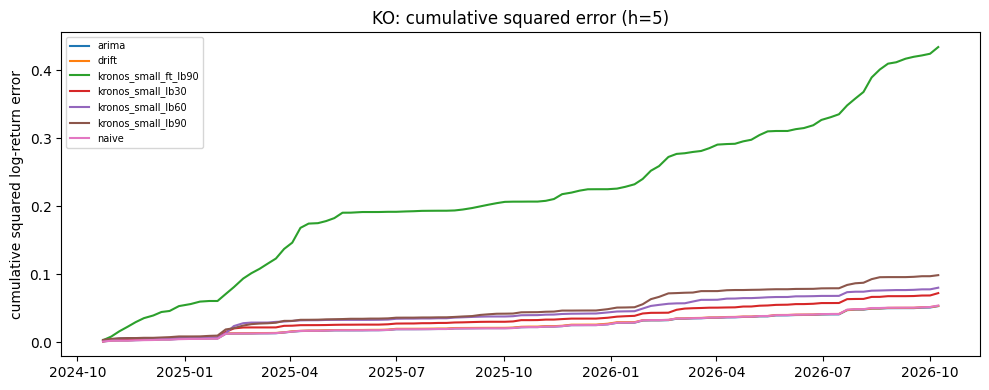

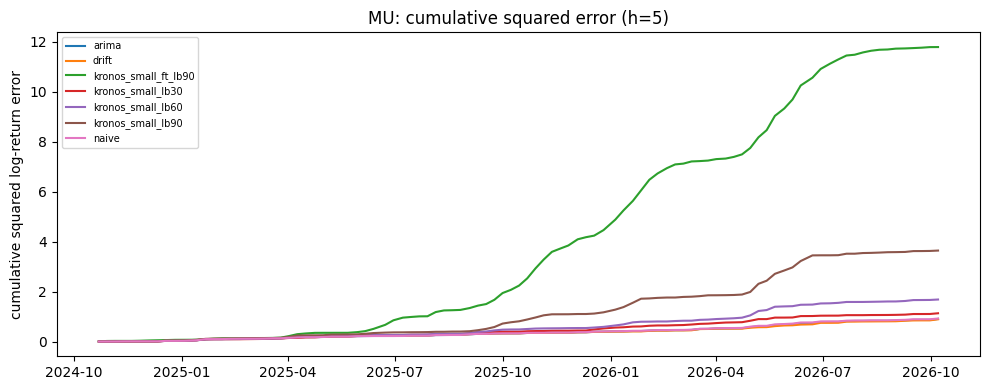

In [2]:
for tk in tickers:
    g = term[term["ticker"] == tk]
    fig, ax = plt.subplots(figsize=(10, 4))
    for m in models:
        gm = g[g["model"] == m]
        ax.plot(gm["origin"], gm["sq"].cumsum(), label=m)
    ax.set(title=f"{tk}: cumulative squared error (h={H})", ylabel="cumulative squared log-return error")
    ax.legend(fontsize=7); plt.tight_layout(); plt.show()


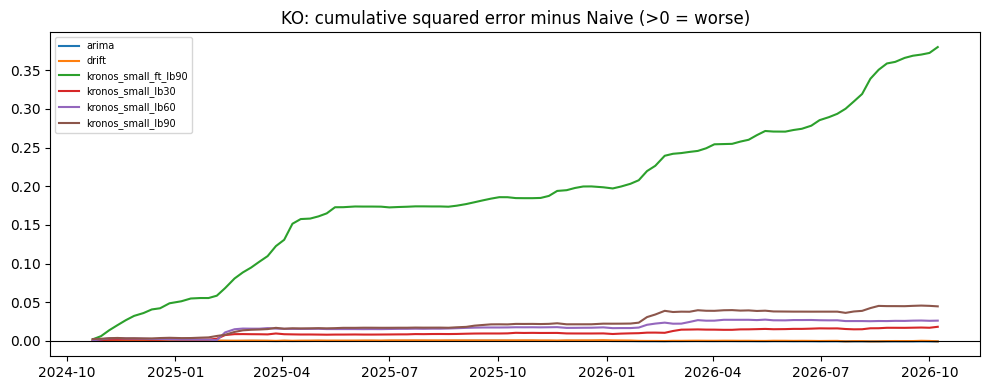

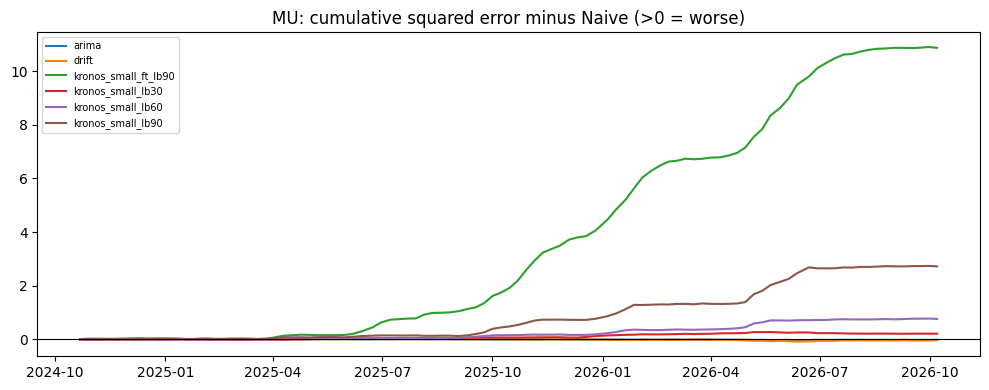

In [3]:
for tk in tickers:
    g = term[term["ticker"] == tk]
    base = g[g["model"] == "naive"].set_index("origin")["sq"].cumsum()
    fig, ax = plt.subplots(figsize=(10, 4))
    for m in models:
        if m == "naive":
            continue
        gm = g[g["model"] == m].set_index("origin")["sq"].cumsum()
        ax.plot(gm.index, gm - base.reindex(gm.index), label=m)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"{tk}: cumulative squared error minus Naive (>0 = worse)")
    ax.legend(fontsize=7); plt.tight_layout(); plt.show()


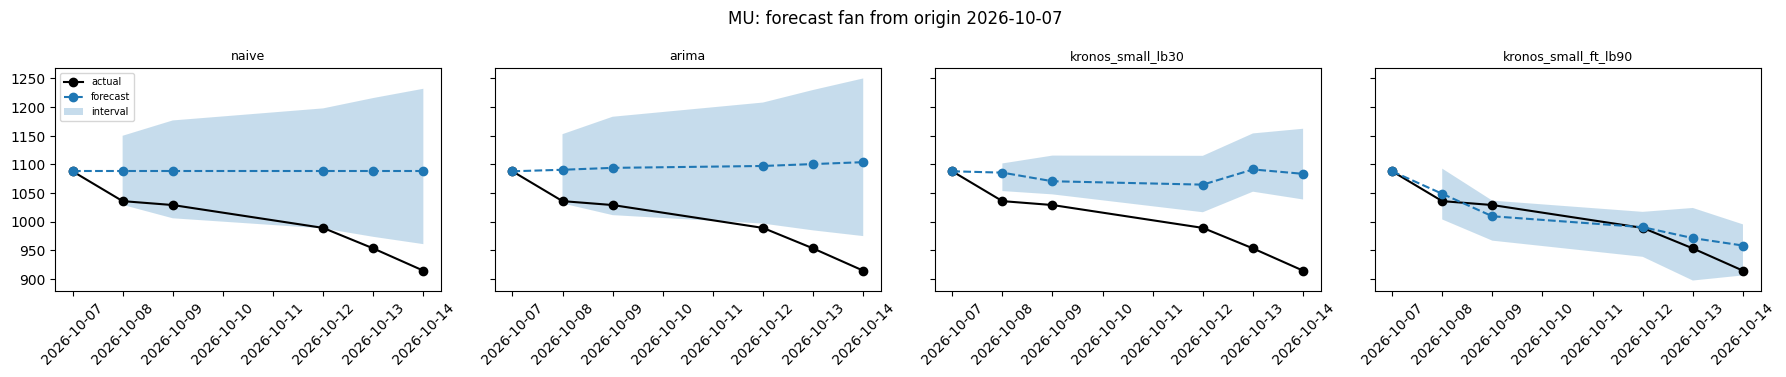

In [4]:
TICKER = "MU"
SHOW = ["naive", "arima", "kronos_small_lb30", "kronos_small_ft_lb90"]
SHOW = [m for m in SHOW if m in models]
ORIGIN_IDX = -1

origins = np.sort(df.loc[df["ticker"] == TICKER, "origin"].unique())
o = origins[ORIGIN_IDX]

fig, axes = plt.subplots(1, len(SHOW), figsize=(4.5 * len(SHOW), 3.8), sharey=True, squeeze=False)
for ax, m in zip(axes[0], SHOW):
    g = df[(df["ticker"] == TICKER) & (df["model"] == m) & (df["origin"] == o)].sort_values("h")
    last = g["last"].iloc[0]
    x = pd.concat([pd.Series([o]), g["target_date"]]).to_numpy()
    ax.plot(x, np.r_[last, g["actual"]], "ko-", label="actual")
    ax.plot(x, np.r_[last, g["pred"]], "--o", label="forecast")
    ax.fill_between(g["target_date"], g["lower"], g["upper"], alpha=0.25, label="interval")
    ax.set_title(m, fontsize=9); ax.tick_params(axis="x", rotation=45)
axes[0][0].legend(fontsize=7)
fig.suptitle(f"{TICKER}: forecast fan from origin {pd.Timestamp(o).date()}")
plt.tight_layout(); plt.show()


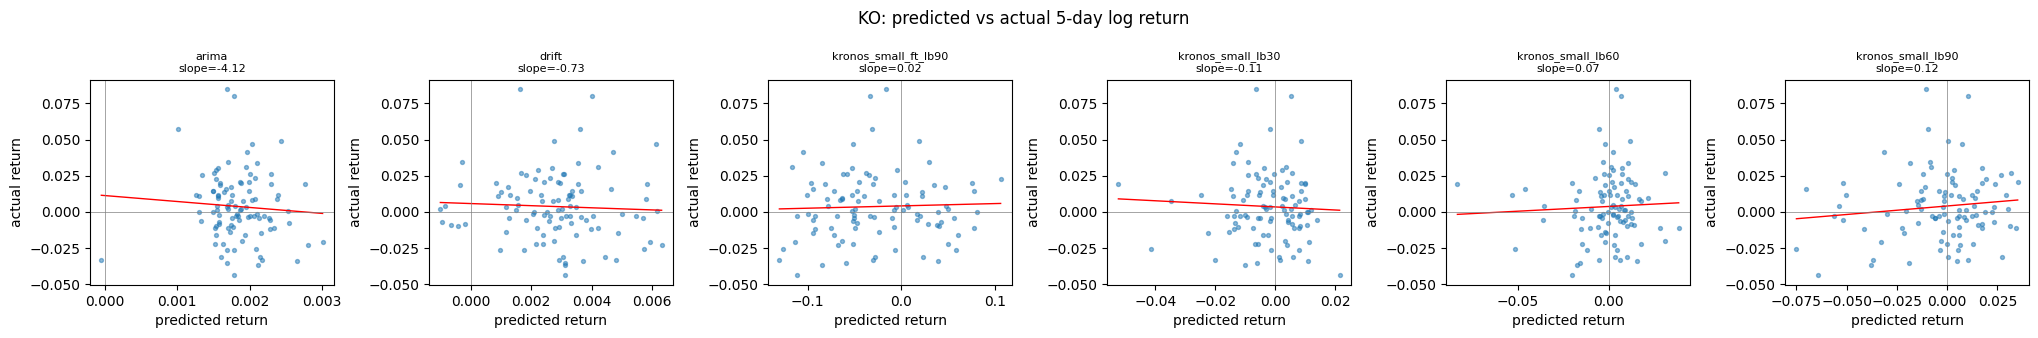

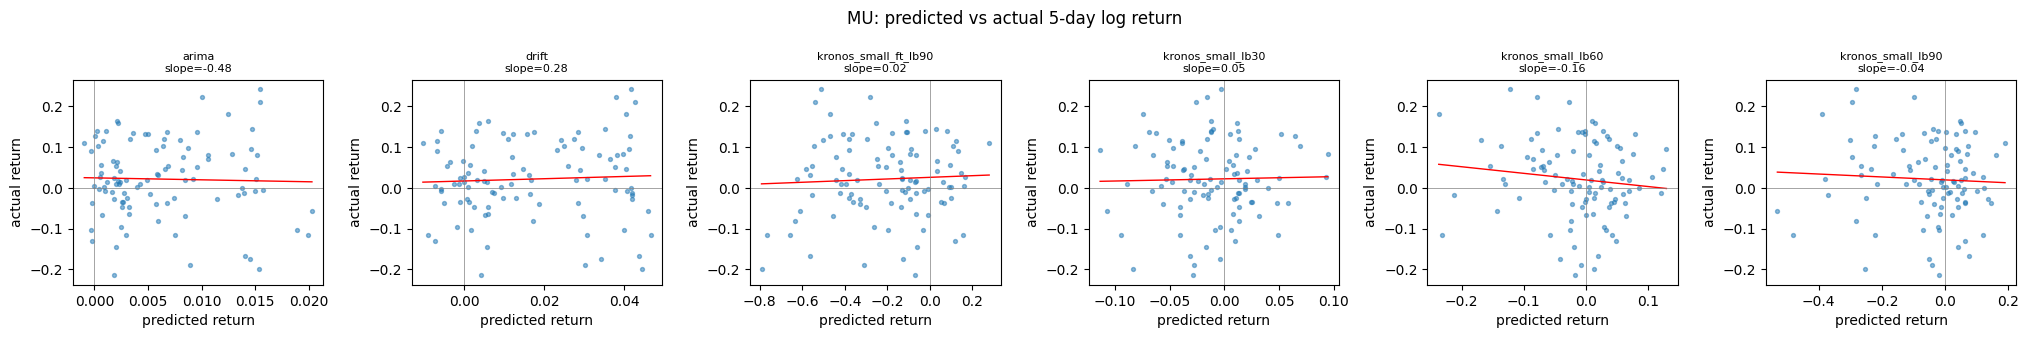

In [5]:
for tk in tickers:
    g = term[term["ticker"] == tk]
    ms = [m for m in models if m != "naive"]
    fig, axes = plt.subplots(1, len(ms), figsize=(3.4 * len(ms), 3.4), squeeze=False)
    for ax, m in zip(axes[0], ms):
        gm = g[g["model"] == m]
        ax.scatter(gm["ret_pred"], gm["ret_act"], s=8, alpha=0.5)
        slope, icpt = np.polyfit(gm["ret_pred"], gm["ret_act"], 1)
        xs = np.linspace(gm["ret_pred"].min(), gm["ret_pred"].max(), 50)
        ax.plot(xs, icpt + slope * xs, "r-", lw=1)
        ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
        ax.set_title(f"{m}\nslope={slope:.2f}", fontsize=8)
        ax.set_xlabel("predicted return"); ax.set_ylabel("actual return")
    fig.suptitle(f"{tk}: predicted vs actual {H}-day log return")
    plt.tight_layout(); plt.show()


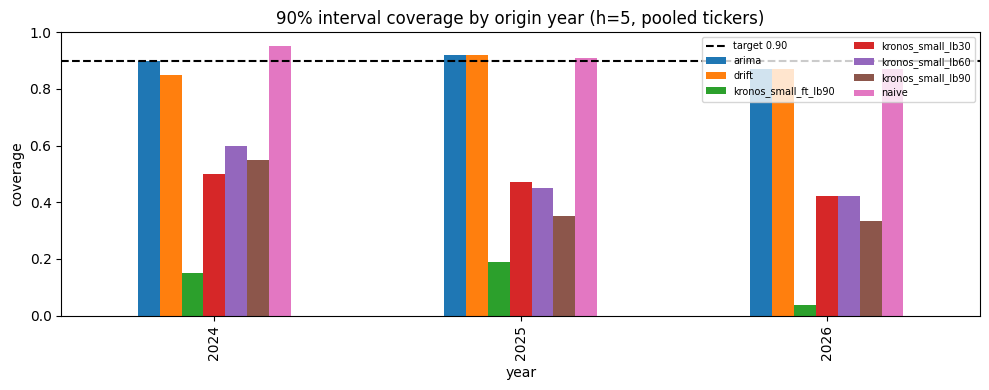

model,arima,drift,kronos_small_ft_lb90,kronos_small_lb30,kronos_small_lb60,kronos_small_lb90,naive
year,,,,,,,
2024,0.900,0.850,0.150,0.500,0.600,0.550,0.950
2025,0.920,0.920,0.190,0.470,0.450,0.350,0.910
2026,0.872,0.872,0.038,0.423,0.423,0.333,0.872


In [6]:
cov = (term.assign(year=term["origin"].dt.year)
           .groupby(["year", "model"])["inside"].mean().unstack("model"))
ax = cov.plot.bar(figsize=(10, 4))
ax.axhline(0.9, color="k", ls="--", label="target 0.90")
ax.set(title=f"90% interval coverage by origin year (h={H}, pooled tickers)", ylabel="coverage", ylim=(0, 1))
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
cov.round(3)
